In [41]:
import numpy as np
import pandas as pd

In [42]:
df = pd.read_csv("retail_sales_dataset.csv")
df.head()

,order_id,date,product,category,price,quantity,city,payment_method,rating,discount
0,ORD1001,2025-02-02,USB-C Hub,Accessories,1799,5,Noida,Credit Card,3.0,5.0
1,ORD1002,2025-10-10,Webcam,Electronics,3299,5,Jaipur,Net Banking,2.0,15.0
2,ORD1003,2025-08-27,Phone Stand,Accessories,379,3,Ahmedabad,Credit Card,5.0,0.0
3,ORD1004,2025-06-10,Bluetooth Speaker,Electronics,2199,5,Mumbai,Net Banking,3.0,20.0
4,ORD1005,2025-06-08,USB-C Hub,Accessories,1799,3,Mumbai,Debit Card,1.0,0.0


In [43]:
df.isnull().sum()

order_id           0
date               0
product            0
category           0
price              0
quantity           0
city               8
payment_method     7
rating            15
discount           5
dtype: int64

In [44]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   order_id        500 non-null    object 
 1   date            500 non-null    object 
 2   product         500 non-null    object 
 3   category        500 non-null    object 
 4   price           500 non-null    int64  
 5   quantity        500 non-null    int64  
 6   city            492 non-null    object 
 7   payment_method  493 non-null    object 
 8   rating          485 non-null    float64
 9   discount        495 non-null    float64
dtypes: float64(2), int64(2), object(6)
memory usage: 39.2+ KB


In [45]:
df.isnull().sum() / len(df) * 100

order_id          0.0
date              0.0
product           0.0
category          0.0
price             0.0
quantity          0.0
city              1.6
payment_method    1.4
rating            3.0
discount          1.0
dtype: float64

In [46]:
df["rating"] = df["rating"].fillna(df["rating"].median())
df["discount"] = df["discount"].fillna(df["discount"].median())
df["city"] = df["city"].fillna("Unknown")
df["payment_method"] = df["payment_method"].fillna("Unknown")

In [47]:
df.isnull().sum()

order_id          0
date              0
product           0
category          0
price             0
quantity          0
city              0
payment_method    0
rating            0
discount          0
dtype: int64

In [48]:
df.duplicated().sum()

np.int64(0)

In [49]:
df.isnull().sum()

order_id          0
date              0
product           0
category          0
price             0
quantity          0
city              0
payment_method    0
rating            0
discount          0
dtype: int64

In [50]:
df["revenue"] = df["price"]*df["quantity"]
df["revenue"]

0       8995
1      16495
2       1137
3      10995
4       5397
       ...  
495     7497
496     1197
497     3995
498     1497
499      598
Name: revenue, Length: 500, dtype: int64

In [51]:
df.head()

,order_id,date,product,category,price,quantity,city,payment_method,rating,discount,revenue
0,ORD1001,2025-02-02,USB-C Hub,Accessories,1799,5,Noida,Credit Card,3.0,5.0,8995
1,ORD1002,2025-10-10,Webcam,Electronics,3299,5,Jaipur,Net Banking,2.0,15.0,16495
2,ORD1003,2025-08-27,Phone Stand,Accessories,379,3,Ahmedabad,Credit Card,5.0,0.0,1137
3,ORD1004,2025-06-10,Bluetooth Speaker,Electronics,2199,5,Mumbai,Net Banking,3.0,20.0,10995
4,ORD1005,2025-06-08,USB-C Hub,Accessories,1799,3,Mumbai,Debit Card,1.0,0.0,5397


In [52]:
total_revenue = df["revenue"].sum()
total_revenue

np.int64(3635152)

In [53]:
category_revenue = df.groupby("category")["revenue"].sum()
print(category_revenue.sort_values(ascending=False))

highest_category = category_revenue.idxmax()
print("Highest revenus is " ,highest_category)

category
Electronics    2104609
Home Office     739932
Accessories     492005
Lifestyle       246170
Stationery       52436
Name: revenue, dtype: int64
Highest revenus is  Electronics


In [54]:
high_elect = df.groupby("product")["revenue"].sum()
print(high_elect.sort_values(ascending=False).head())

product
Monitor         670748
Office Chair    604733
External SSD    544941
Webcam          305818
Headphones      255828
Name: revenue, dtype: int64


In [55]:
df["city"] = df["city"].fillna("Unknown")
top_city = df.groupby("city")["revenue"].sum()
print(top_city.sort_values(ascending=False).head(20))

city
Noida        388290
Kolkata      347522
Ahmedabad    339790
Bengaluru    322640
Delhi        314696
Hyderabad    306089
Jaipur       287047
Gurugram     273800
Chennai      256740
Mumbai       255844
Lucknow      254269
Pune         244347
Unknown       44078
Name: revenue, dtype: int64


In [56]:
pay_method = df.groupby("payment_method")["revenue"].sum()
print(pay_method.sort_values(ascending=False))

payment_method
Cash           832182
Credit Card    808575
UPI            780923
Net Banking    633366
Debit Card     568817
Unknown         11289
Name: revenue, dtype: int64


In [57]:
cus_rating = df.groupby("product")["rating"].mean()
cus_rating.sort_values(ascending=False)

product
Monitor                4.047619
Wireless Mouse         4.041667
Webcam                 4.032258
Pen Set                4.031250
Backpack               3.975610
Power Bank             3.941176
Water Bottle           3.923077
USB-C Hub              3.906250
External SSD           3.875000
Phone Stand            3.875000
Headphones             3.843750
Notebook Set           3.837838
Mechanical Keyboard    3.818182
Desk Mat               3.800000
Office Chair           3.750000
Desk Lamp              3.687500
Laptop Stand           3.625000
Bluetooth Speaker      3.608696
Name: rating, dtype: float64

In [58]:
avg_discount = df.groupby("category")["discount"].mean()
avg_discount.sort_values(ascending=False)

category
Lifestyle      10.223881
Home Office     8.538462
Accessories     7.896825
Electronics     7.456647
Stationery      6.956522
Name: discount, dtype: float64

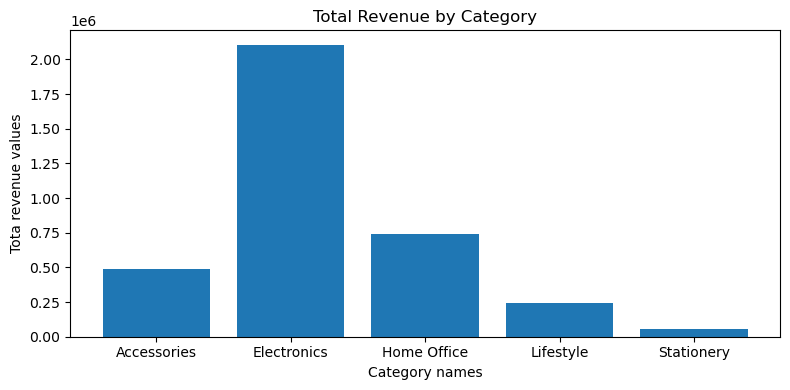

In [59]:
import matplotlib.pyplot as plt

cate_revenue = df.groupby("category")["revenue"].sum()

plt.figure(figsize=(8,4))
plt.bar(cate_revenue.index , cate_revenue.values)
plt.title("Total Revenue by Category")
plt.xlabel("Category names")
plt.ylabel("Tota revenue values")

plt.tight_layout()
plt.show()

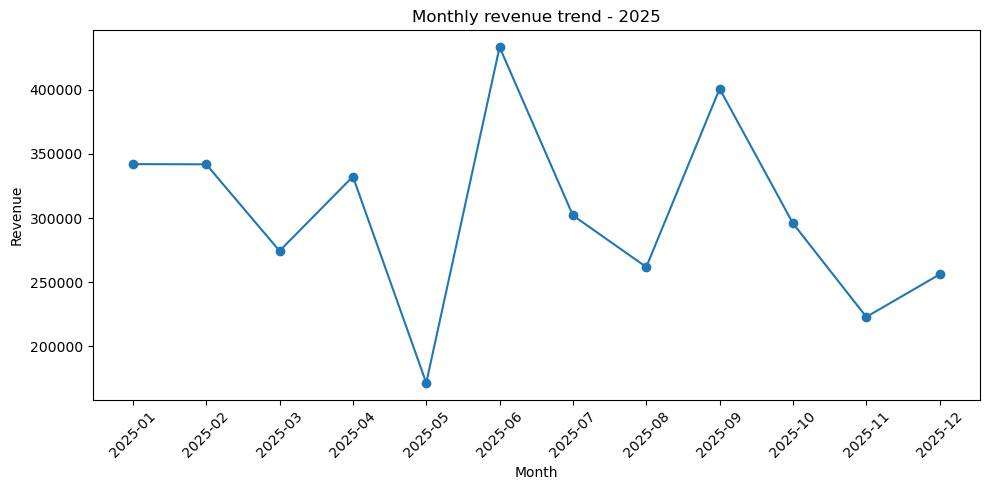

In [60]:
#Convert date column into date time
df["date"] = pd.to_datetime(df["date"])

#Calculate total revenue for each month
monthly_revenue = df.groupby(df["date"].dt.to_period("M"))["revenue"].sum()

#Create line chart
plt.figure(figsize=(10,5))
plt.plot(monthly_revenue.index.astype(str) , monthly_revenue.values , marker="o")

#Title and labels
plt.title("Monthly revenue trend - 2025")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation = 45)
plt.tight_layout()
plt.show()

01 · CATEGORY PERFORMANCE

Electronics leads revenue

Electronics generated ₹21,04,609, much more than the next-highest category, Home Office, at ₹7,39,932.


02 · PRODUCT PERFORMANCE

Monitor is the top revenue-generating product

Monitors generated ₹6,70,748, followed by Office Chairs at ₹6,04,733.


03 · CITY PERFORMANCE

Noida generated the highest city-wise revenue

Noida contributed ₹3,88,290, followed by Kolkata at ₹3,47,522. The "Unknown" group represents orders with missing city information, not an actual city.


04 · CUSTOMER RATINGS

Monitor ratings are strong

Monitors had an average rating of approximately 4.05/5. Bluetooth Speakers had the lowest average rating among the products, at approximately 3.61/5.


05 · MONTHLY PERFORMANCE

Revenue fluctuated throughout the year

June had the highest monthly revenue at approximately ₹4.33 lakh, while May had the lowest at approximately ₹1.71 lakh.

In [61]:
#Calculate net revenue after discount
df["net_revenue"] = df["revenue"] * (1 - df["discount"] / 100)

#Calculate total net revenue
total_net_revenue = df["net_revenue"].sum()
print("Total net revenue", total_net_revenue)

#Compare with original revenue 
total_revenue = df["revenue"].sum()
print("Original revenue", total_revenue)
print("Revenue lost to discounts" , total_revenue - total_net_revenue)

Total net revenue 3358583.75
Original revenue 3635152
Revenue lost to discounts 276568.25


In [62]:
#Calculate net revenue for each category 
category_net_revenue = df.groupby("category")["net_revenue"].sum()
print(category_net_revenue.sort_values(ascending=False))

highest_category = category_net_revenue.idxmax()
print("Highest :",highest_category)

category
Electronics    1959117.40
Home Office     673743.20
Accessories     456334.45
Lifestyle       220330.05
Stationery       49058.65
Name: net_revenue, dtype: float64
Highest : Electronics


In [75]:
#Calculate discount amount for each order
df["discount_amount"] = df["revenue"] - df["net_revenue"]

#Calculate total discount amount for each category
total_discount_cat = df.groupby("category")["discount_amount"].sum()
print(total_discount_cat.sort_values(ascending=False))

#Highest discountt
highest_cat_discount = total_discount_cat.idxmax()
print("Highest category :", highest_cat_discount)


category
Electronics    145491.60
Home Office     66188.80
Accessories     35670.55
Lifestyle       25839.95
Stationery       3377.35
Name: discount_amount, dtype: float64
Highest category : Electronics


In [81]:
df.head()

,order_id,date,product,category,price,quantity,city,payment_method,rating,discount,revenue,net_revenue,discount_amount
0,ORD1001,2025-02-02,USB-C Hub,Accessories,1799,5,Noida,Credit Card,3.0,5.0,8995,8545.25,449.75
1,ORD1002,2025-10-10,Webcam,Electronics,3299,5,Jaipur,Net Banking,2.0,15.0,16495,14020.75,2474.25
2,ORD1003,2025-08-27,Phone Stand,Accessories,379,3,Ahmedabad,Credit Card,5.0,0.0,1137,1137.00,0.00
3,ORD1004,2025-06-10,Bluetooth Speaker,Electronics,2199,5,Mumbai,Net Banking,3.0,20.0,10995,8796.00,2199.00
4,ORD1005,2025-06-08,USB-C Hub,Accessories,1799,3,Mumbai,Debit Card,1.0,0.0,5397,5397.00,0.00


In [96]:
product_price = df.groupby("product")["price"].max()
product_price.sort_values(ascending=False)
highest_product = product_price.idxmax()
highest_price = product_price.max()

print("Highest-priced product:", highest_product)
print("Price:", highest_price)

Highest-priced product: Monitor
Price: 13649


## Business Insights

After analyzing the retail sales dataset, I found some interesting things about the sales, products, customers, and discounts.

### 1. Category-wise Sales
Electronics generated the highest revenue of ₹21,04,609. Home Office came second with ₹7,39,932. This shows that Electronics performed much better than the other categories.

### 2. Top Products
Monitor generated the highest revenue of ₹6,70,748. Office Chair and External SSD were also among the top revenue-generating products.

### 3. City-wise Sales
Noida had the highest revenue of ₹3,88,290, followed by Kolkata with ₹3,47,522. So, Noida performed the best in terms of revenue among all the cities.

### 4. Payment Methods
Cash was the most revenue-generating payment method, with ₹8,32,182. Credit Card came very close with ₹8,08,575.

### 5. Customer Ratings
Monitor had the highest average rating of around 4.05, while Bluetooth Speaker had the lowest average rating of around 3.61. Overall, most products received good customer ratings.

### 6. Monthly Revenue
I noticed that sales were not the same every month. June had the highest revenue (around ₹4.33 lakh), while May had the lowest (around ₹1.71 lakh). There was also a noticeable increase in revenue after May.

### 7. Discount Analysis
Electronics had the highest total discount amount of ₹1,45,491.60. However, Lifestyle had the highest average discount percentage of around 10.22%.

### 8. Revenue After Discounts
The total original revenue was ₹36,35,152. After applying discounts, the net revenue became ₹33,58,583.75. The total discount amount was ₹2,76,568.25.

### My Overall Observation
From this project, I understood how sales data can be analyzed to find useful information about products, categories, cities, and customer ratings. Electronics was the best-performing category in our dataset, and Monitor generated the highest revenue among individual products. I also learned how discounts affect the final revenue and how visualizations make it easier to understand sales trends.